# Introduction

Forecasting crop yields is one of the key variables in determing agricultural commodity market supply and use balances. When done at the national level in the United States, for any crop, the yield expectation is a function of longer-run trends in productivity enhancement and adoption of new technologies, as well as shorter-run variables such as geographic distribution of production, the weather and environment in those areas, and how the environment influences the crop at multiple stages of crop development.  For the U.S. Deparment of Agriculture, its World Agricultural Supply and Demand Estimates (WASDE) reports are an institutional report that provide information to policy makers and the public to help inform decision making for all stakeholders.

National yield figures are aggeregations of more granular data. For NASS, the national average yield is a function of local-level, survey-based processes.  As a result, forecasting national average yields typically requires capturing state-level information and generalizing it into the national figure.  Most previous approaches perform this generalization function in construction of the independent variables that are used in a linear regression with national yield as the dependent variable.  For example, precipitation levels are collected at a state-level and then weighted by the selected state's relative area to generate a metric to control for the impact on national production.  This approach has proven to be effective in providing objective estimates for national yields, under the assumption of normal weather conditions, prior the availabilty of the state-level survey results.  Additionally, it is a process that is able to be maintained and implemented under strict timelines with dynamic information environments.  The calculation must be available at the time of the monthly WASDE report's construction or it is of little value for that analysis.

These control variables represent complex natural and biological systems that have distinct statistitcal relationships in specific geographies, however.  For instance, weighted-average precipitation control variables do not distinguish between moderate drought throughout the key growing regions and severe drought within a specific part of the key growing region.  Additionally, the crop response to abnormal weather conditions can vary in different parts of the country due agronomic and farm management differences.  

An alternative approach that captures such granular, local dynamics would be to perform the generalization and aggregation process on state-level estimates, rather than on the control variables. This approach models each corn-producing state separately, weighing the model results based on the relative importance of that state's contribution to the national production totals. Doing such analysis is more calculation-intensive. Such processes would have been considered burdensome and likely unwieldy to implement for reports like the WASDE. The more intensive approach is currently more practical, however, than it would have been at the time of similar national yield model procedures that have been put to practial use. This is because of the improvements in data delivery systems and tools to develop programmatic approaches that can maintain and update the models.  The proposed approach would augment and potentially improve the mid-point forecasts that inform U.S. crop production forecasts.

Additonally, modeling the more granular data allows for additional analysis on the stochastic variability of the forecasts and how model results change as weather and crop conditions vary. This can provide an improved perspective on how crop forecasts can vary and the probability distributions associated with yield forecasts under dynamic conditions.

In [33]:
#import all needed libraries and modules
import os
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

print('Modules imported')

Modules imported


# Weather Data

The weather data used for these calculations are the the National Oceanic and Atmospheric Administration's (NOAA) state-level monthly data. The data set is continuous going back to 1895, including precipitaiton and max temperatures used as key variables to control for weather conditions during the growing season.

In [34]:
#import weather data csv

## Date associated with files
procdate = 'https://www1.ncdc.noaa.gov/pub/data/cirs/climdiv/procdate.txt'
date = requests.get(procdate).text[:]

## data url structures (to be added with the date to get the complete URL)

pcpn_st_url = 'https://www1.ncdc.noaa.gov/pub/data/cirs/climdiv/climdiv-pcpnst-v1.0.0-'
tmax_st_url = 'https://www1.ncdc.noaa.gov/pub/data/cirs/climdiv/climdiv-tmaxst-v1.0.0-'
tmin_st_url = 'https://www1.ncdc.noaa.gov/pub/data/cirs/climdiv/climdiv-tminst-v1.0.0-'
tmpc_st_url = 'https://www1.ncdc.noaa.gov/pub/data/cirs/climdiv/climdiv-tmpcst-v1.0.0-'

st_list = []
st_url_list = [pcpn_st_url, tmax_st_url, tmin_st_url, tmpc_st_url]

for i in st_url_list:
    fmt_url = str(i) + str(date)
    st_list.append(fmt_url)

# Import and format data

cols = ['code', '01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12']
element_dict = {
    '01' : 'Precipitation', '02' : 'Average Temperature', '05' : 'PDSI', '06' : 'PHDI', '07' : 'ZNDX',
    '08' : 'PMDI', '25' : 'Heating Degree Days', '26' : 'Cooling Degree Days', '27' : 'Maximum Temperature',
    '28' : 'Minimum Temperature', '71' : '1-month Standardized Precipitation Index', '72' : '2-month Standardized Precipitation Index',
    '73' : '3-month Standardized Precipitation Index', '74' : '6-month Standardized Precipitation Index',
    '75' : '9-month Standardized Precipitation Index', '76' : '12-month Standardized Precipitation Index',
    '77' : '24-month Standardized Precipitation Index'
    }

state_dict = {
    '001':'Alabama', '030': 'New York',
    '002':'Arizona', '031':'North Carolina',
    '003':'Arkansas', '032':'North Dakota',
    '004':'California', '033':'Ohio',
    '005':'Colorado', '034':'Oklahoma',
    '006':'Connecticut', '035':'Oregon',
    '007':'Delaware', '036':'Pennsylvania',
    '008':'Florida', '037':'Rhode Island',
    '009':'Georgia','038':'South Carolina',
    '010':'Idaho', '039':'South Dakota',
    '011':'Illinois', '040':'Tennessee',
    '012':'Indiana', '041':'Texas',
    '013':'Iowa', '042':'Utah',
    '014':'Kansas', '043':'Vermont',
    '015':'Kentucky', '044':'Virginia',
    '016':'Louisiana', '045':'Washington',
    '017':'Maine', '046':'West Virginia',
    '018':'Maryland', '047':'Wisconsin',
    '019':'Massachusetts', '048':'Wyoming',
    '020':'Michigan','050':'Alaska',     
    '021':'Minnesota', '101':'Northeast Region',
    '022':'Mississippi', '102':'East North Central Region',
    '023':'Missouri', '103':'Central Region',
    '024':'Montana', '104':'Southeast Region',  
    '025':'Nebraska', '105':'West North Central Region', 
    '026':'Nevada', '106':'South Region',
    '027':'New Hampshire', '107':'Southwest Region',  
    '028':'New Jersey', '108':'Northwest Region',  
    '029':'New Mexico', '109':'West Region',
    '110':'National (contiguous 48 States)',
    
    '250':'Spring Wheat Belt (area weighted)',
    '255':'Primary Hard Red Winter Wheat Belt (area weighted)',
    '256':'Winter Wheat Belt (area weighted)',
    '260':'Primary Corn and Soybean Belt (area weighted)',
    '261':'Corn Belt (area weighted)',
    '262':'Soybean Belt (area weighted)',
    '265':'Cotton Belt (area weighted)',
    
    }

st_mly = pd.DataFrame(columns=['date', 'code', 'state', 'element', 'div', 'year', 'month', 'value'])

nan_list = ['-99.99', '-99.90', '99.90', '-9.99', '-9999', '-99.99', '9.99']

col_specs = [(0, 10), (11, 17), (18, 24), (25, 31), (32, 38), (39, 45), (46, 52), (53, 59), (60, 66), (67, 73), (74, 80), (81, 87), (88, 94)]

for i in st_list:
    noaa_df = pd.read_fwf(i, colspecs=col_specs, engine='python', header=None, dtype='str')
    noaa_df = noaa_df.replace(nan_list, np.nan)
    noaa_df.columns = cols
    noaa_df = noaa_df.melt(id_vars = ['code'], var_name='month', value_name='value')
    noaa_df['state'] = noaa_df['code'].str.slice(0, 3)
    noaa_df['div'] = noaa_df['code'].str.slice(3, 4)
    noaa_df['element'] = noaa_df['code'].str.slice(4, 6)
    noaa_df['year'] = noaa_df['code'].str.slice(6, )
    noaa_df['date'] = pd.to_datetime(noaa_df['year'] + noaa_df['month'] + '01')
    noaa_df['value'] = noaa_df['value'].astype('float64')
    noaa_df['id'] = noaa_df['code'] + noaa_df['month']
    noaa_df = noaa_df.sort_values(['year', 'month', 'state'])
    st_mly = pd.concat([st_mly, noaa_df])
    print('Success: ' + str(i))

st_mly = st_mly.set_index('date')
st_mly['element_desc'] = st_mly['element'].map(element_dict)
st_mly['state_name'] = st_mly['state'].map(state_dict)

print(st_mly.info())


Success: https://www1.ncdc.noaa.gov/pub/data/cirs/climdiv/climdiv-pcpnst-v1.0.0-20231206

Success: https://www1.ncdc.noaa.gov/pub/data/cirs/climdiv/climdiv-tmaxst-v1.0.0-20231206

Success: https://www1.ncdc.noaa.gov/pub/data/cirs/climdiv/climdiv-tminst-v1.0.0-20231206

Success: https://www1.ncdc.noaa.gov/pub/data/cirs/climdiv/climdiv-tmpcst-v1.0.0-20231206

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 599184 entries, 1895-01-01 to 2023-12-01
Data columns (total 10 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   code          599184 non-null  object 
 1   state         599184 non-null  object 
 2   element       599184 non-null  object 
 3   div           599184 non-null  object 
 4   year          599184 non-null  object 
 5   month         599184 non-null  object 
 6   value         598793 non-null  float64
 7   id            599184 non-null  object 
 8   element_desc  599184 non-null  object 
 9   state_name    407232 non

In [35]:
print(st_mly[
             (st_mly['month'].isin(['05', '06', '07', '08']))&
             (st_mly['value'].notnull()&
             (st_mly['state_name']=='South Dakota')&
             (st_mly['element_desc']=='Precipitation'))])

                  code state element div  year month  value            id   
date                                                                        
1895-05-01  0390011895   039      01   0  1895    05   2.26  039001189505  \
1895-06-01  0390011895   039      01   0  1895    06   4.16  039001189506   
1895-07-01  0390011895   039      01   0  1895    07   1.36  039001189507   
1895-08-01  0390011895   039      01   0  1895    08   1.30  039001189508   
1896-05-01  0390011896   039      01   0  1896    05   2.33  039001189605   
...                ...   ...     ...  ..   ...   ...    ...           ...   
2022-08-01  0390012022   039      01   0  2022    08   1.83  039001202208   
2023-05-01  0390012023   039      01   0  2023    05   2.97  039001202305   
2023-06-01  0390012023   039      01   0  2023    06   4.20  039001202306   
2023-07-01  0390012023   039      01   0  2023    07   2.56  039001202307   
2023-08-01  0390012023   039      01   0  2023    08   3.57  039001202308   

# Brief review of relevent literature

## Overall objectives of this approach

TEXT HERE

# Development of the model

In [36]:
# import the relevent data

# Defined variables and objects
mdl_start_year = 1980 # Constrained by planting progress data availability
mdl_forecast_year = 2023
plt_prog_toggle = True # toggles between using actual planting progress (True) or force "normal" adjusted planting progress rate of 1 (False)
plt_prog_month = 5
plt_prog_day = 20 #Current limited to May 21 due to limitations of reported planting progress by state in some years after this date, which results in dropping years from datasets
num_of_draws = 10000 #use >10,000 draws for production runs
weather_draw_start_year = 1895
print('variables set')

variables set


## Importing the NASS data from API

The following function is used to pull USDA production, area, yield, and planting progress from USDA's QuickStats API.

In [37]:
api_key_nass = os.environ.get('NASS_API_KEY')

nass_get_base = 'http://quickstats.nass.usda.gov/api/api_GET/'

def PL_QS_pull(Payload):
    '''
    Takes a payload for a NASS QuickStats
    API and returns a pandas DataFrame with
    Values column formatted as a numeric object
    '''
    r = requests.get(nass_get_base, params=Payload)
    r_json = r.json()   
    r_df = pd.DataFrame.from_dict(r_json['data']) 
    #Reformat DF so that data types are appropriate
    r_df['Value'] = r_df['Value'].str.replace(",", "") #need this otherwise to_numeric function converts all to NaN
    r_df['Value'] = pd.to_numeric(r_df['Value'], errors='coerce')
    
    return r_df
print('Complete')

Complete


## Production, area, and yield data

The modeling approach starts by collecting the state-level production data, including historical yields, area planted, and area harvested all from the NASS QuickStates database.

In [38]:
## Payload and API call for annual data

prod_PL = {
    'key': api_key_nass,
    'source_desc':'SURVEY',
    'agg_level_desc':['STATE', 'NATIONAL'],
    'statisticcat_desc':['YIELD', 'AREA PLANTED', 'AREA HARVESTED'],
    'commodity_desc':'CORN',
    'reference_period_desc':['YEAR'],
    'prodn_practice_desc':'ALL PRODUCTION PRACTICES',
    'util_practice_desc':['ALL UTILIZATION PRACTICES', 'GRAIN'],
    'unit_desc':['BU / ACRE', 'ACRES'],
    'year__GE':'1895', 
    'format':'json'
    }
prod_df = PL_QS_pull(prod_PL)
#print(prod_df.info())
prod_fmt = prod_df[
    (prod_df['year'] >= mdl_start_year)
    ]

prod_mdl = prod_fmt.pivot_table(index=['year', 'state_name'], columns='statisticcat_desc', values='Value').reset_index()
prod_mdl['state_name'] = prod_mdl['state_name'].str.title()
prod_mdl = prod_mdl.rename(columns={'AREA HARVESTED':'ah', 'AREA PLANTED':'ap', 'YIELD':'yld', 'Value':'value'})

print('complete')

complete


In [39]:
#print(prod_mdl.head())
#for i in prod_mdl['state_name'].unique():
#    print(str(i), ": ", prod_mdl[prod_mdl['state_name']==str(i)]['year'].unique())

## Planting Progress data

Like the production data, planting progress is reported by NASS through the weekly Crop Progress report. The data is reported weekly, with planting progress reported at the State-level, beginning in March and continuing through June. 

In [40]:
prog_PL = {
    'key': api_key_nass,
    'source_desc':'SURVEY',
    'statisticcat_desc':['PROGRESS'],
    'commodity_desc':'CORN',
    'unit_desc':['PCT PLANTED'],
    'format':'json'
    }
prog_df = PL_QS_pull(prog_PL)
print('progress data completed')

progress data completed


In [41]:
#print(prog_df.info())
#print(prog_df.groupby('state_name').agg(min_year=('year', np.min), max_year=('year', np.max)))

#for i in prog_df['state_name'].unique().tolist():
#    print(str(i), ": ", prog_df[prog_df['state_name']==str(i)]['year'].unique())

State reporting does not typically show records until there is field-level activity. Likewise, once all planting is repoted to be complete, records are no longer submitted. As a result, from year-to-year, records may have different start and ending times based on the specific activity of that particular year, such as good weather conditions that allowed farmers to plant crops early and quickly or poor weather conditions that delayed planting and forced such field work to continue into the summer.  At times, this requires additional imputation of data to ensure data is properly reflected for weeks when data is not reported.

Once collected, the weekly data series in linearly interpolated to daily series. This allows data to be compared across years on an easier basis, since weekly reporting dates and week numbers vary from year-to-year. The approach has a simplifying assumption that planting progress over the course of a week is linear and consistent. While this is not true in practice, due to varying weather conditions that can affect progress from day-to-day, the interpolation is still bounded by reported weekly data points and is deemed suitable for this analysis.

In [42]:
prog_fmt = prog_df[
    (prog_df['year']>=mdl_start_year)
    ]
prog_fmt.loc[:,'week_ending'] = pd.to_datetime(prog_fmt['week_ending'])
prog_fmt.loc[:,'state_name'] = prog_fmt['state_name'].str.title()
prog_fmt = prog_fmt.set_index('week_ending')
prog_mdl = prog_fmt.groupby(['state_name', 'year'])['Value'].resample('D').mean().interpolate().reset_index() #augment to interpolate to 100 percent when reporting stops
prog_mdl = prog_mdl.rename(columns={'Value':'plt_prog'})

print('complete')

complete


In [43]:
#print(prog_fmt[(prog_fmt['state_name']=='North Dakota') &(prog_fmt['year']==1999)])

Finally, to normalize the data series across states and season, a variable is created that compares the current year's progress against the median progress of that state, on that date.

In [44]:
median_prog = prog_mdl.assign(day = prog_mdl.week_ending.dt.day, month = prog_mdl.week_ending.dt.month)
median_prog = median_prog.groupby(['state_name', 'month', 'day']).agg({'plt_prog':np.median}) # used for prediction matrices for all forecast estimates
median_merge = median_prog.reset_index().rename(columns={'plt_prog':'plt_median'})

prog_mdl = prog_mdl.assign(day = prog_mdl.week_ending.dt.day, month = prog_mdl.week_ending.dt.month)
prog_mdl = prog_mdl.merge(median_merge, on=['state_name', 'month', 'day'], how='left')  #.drop(['month', 'day'], axis=1)
prog_mdl['plt_adj'] = prog_mdl['plt_prog']/prog_mdl['plt_median']
prog_mdl_filter = prog_mdl[(prog_mdl['month']==plt_prog_month) & (prog_mdl['day']==plt_prog_day)]
print('complete')

complete


In [45]:
#print(median_prog.loc['Illinois'][-60:-30])
#print(prog_mdl[(prog_mdl['state_name']=='Illinois')&(prog_mdl['day'].between(25, 28))&(prog_mdl['month']==5)].head(40))
#print(prog_mdl.info())
#print(prog_mdl[(prog_mdl['state_name']=='Illinois')&(prog_mdl['year']==2021)])

[]

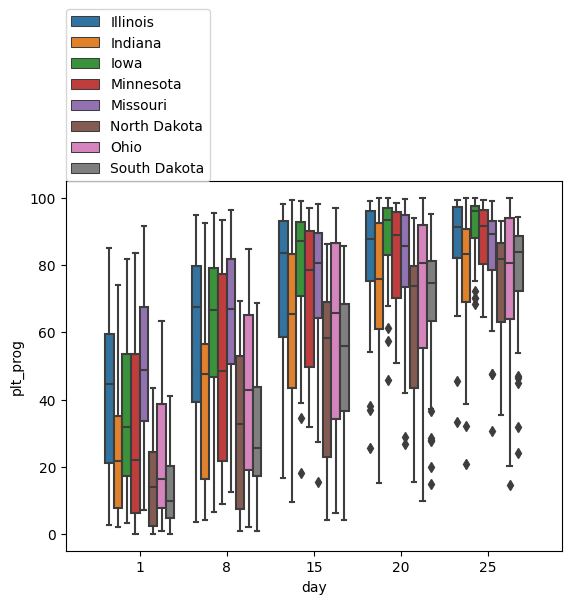

In [46]:

violin_states = ['Illinois', 'Iowa', 'North Dakota', 'Minnesota', 'Missouri', 'Ohio', 'Indiana', 'South Dakota']

sns.boxplot(data=prog_mdl[(prog_mdl.day.isin([1, 8, 15, 20, 25])) & (prog_mdl.month==5) & (prog_mdl.state_name.isin(violin_states))], 
               y='plt_prog', 
               x='day', 
               hue='state_name', 
               dodge = True
              )
plt.legend(loc=(0,1))
plt.plot()

## Bringing in  NOAA weather data

The model uses the state-aggregated weather data calculated by NOAA and available on their website through an FTP.

In [47]:
wx_df = st_mly.reset_index()
#st_mly.to_csv('noaa_state_mdl_data.csv')
print('weather file created')

weather file created


## Formatting the weather data

The key formatting elements to incorporate into the model for crop models are the state-level precipitation and temperature data for the months of May through August. Because weather relationships are not strictly linear, transforming some of the variables nonlinearly is done.

In [48]:
# format weather data

wx_df['date'] = pd.to_datetime(wx_df['date'])

wx_fmt = wx_df[
    (wx_df['date'].dt.month.isin([4, 5, 6, 7, 8])) 
    ]
wx_fmt.loc[:,'col_labs'] = wx_fmt.loc[:,'element_desc'].map({
    'Average Temperature':'temp', 'Maximum Temperature':'max_temp', 'Minimum Temperature':'min_temp', 'Precipitation':'pcpn'
    })
wx_fmt = wx_fmt.assign(
    year = wx_fmt['date'].dt.year,
    month = wx_fmt['date'].dt.month.astype(str)
    )
wx_fmt = wx_fmt.pivot_table(index = ['year', 'month', 'state_name'], columns=['col_labs'], values='value').reset_index()
wx_mdl = wx_fmt.pivot_table(index = ['year', 'state_name'], columns=['month'], values=['max_temp', 'min_temp', 'pcpn', 'temp']).reset_index()

wx_mdl.columns = ['_'.join(col).strip() for col in wx_mdl.columns.values]

wx_mdl = wx_mdl.assign(
    pcpn_6_sq = wx_mdl['pcpn_6']**2,
    pcpn_7_sq = wx_mdl['pcpn_7']**2,
    max_temp_7_sq = wx_mdl['max_temp_7']**2,
    pcpn_8_sq = wx_mdl['pcpn_8']**2,
    max_temp_8_sq = wx_mdl['max_temp_8']**2
    )
wx_mdl = wx_mdl.rename(columns={'year_':'year', 'state_name_':'state_name'})
#print(wx_mdl.query('state_name == "Missouri" & year == "1934"'))
print('complete')

/tmp/ipykernel_1649142/3293826668.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  wx_fmt.loc[:,'col_labs'] = wx_fmt.loc[:,'element_desc'].map({


complete


## Visualization of weather data

TEXT

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


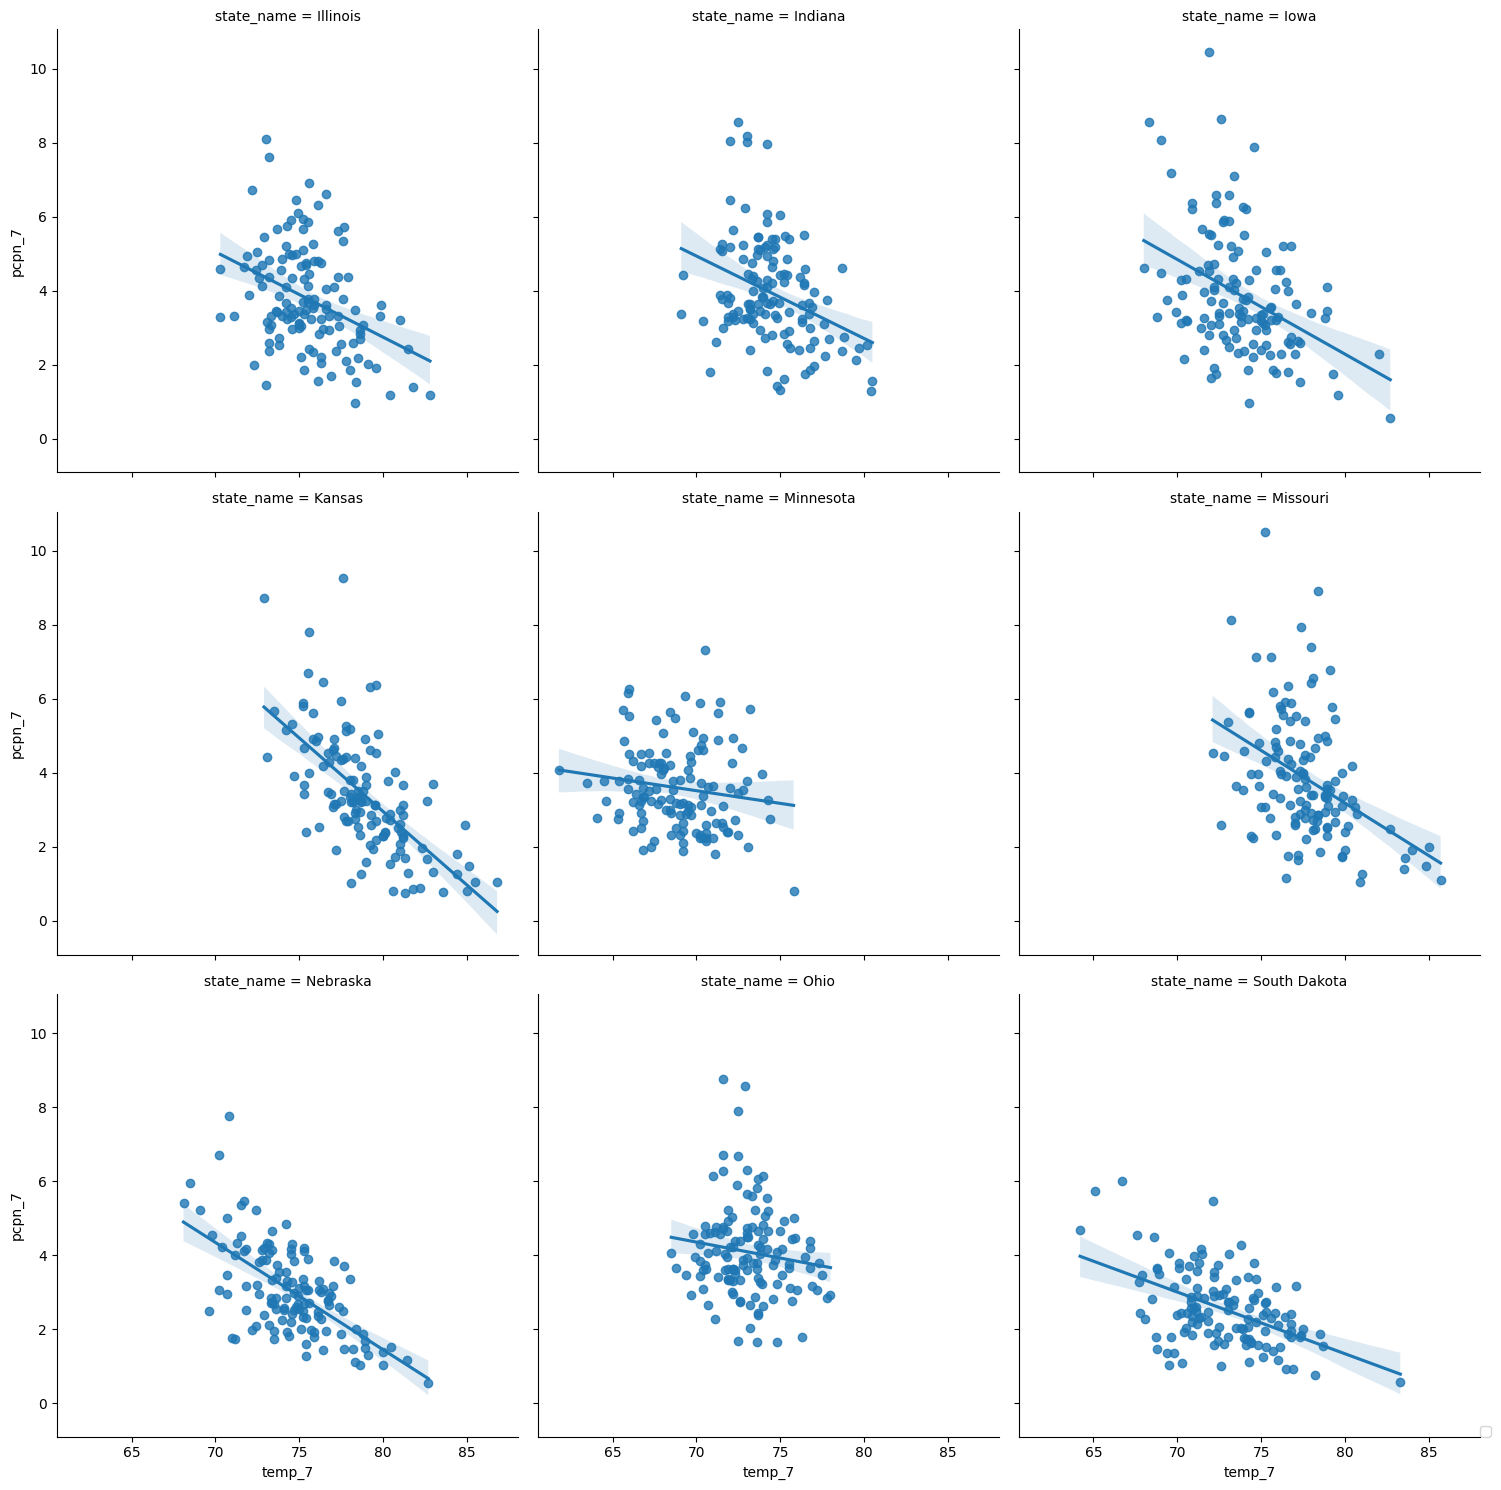

In [50]:
state_wx_list = ['Illinois', 'Iowa', 'South Dakota', 'Minnesota', 'Nebraska', 'Indiana', 'Kansas', 'Missouri', 'Ohio']

wx_mdl_viz= wx_mdl[wx_mdl['state_name'].isin(state_wx_list)]
# wx_mdl_viz['outlier']=np.where(wx_mdl_viz['year'].isin([2004, 2009, 2014, 2016, 2017]), 3, 1).astype('float64')

sns.lmplot(x='temp_7', y='pcpn_7', col='state_name', col_wrap=3, data=wx_mdl_viz)  # hue='outlier', 'alpha=0.5,  
plt.legend(loc=(1, 0))
plt.show()

## Merging the NASS and NOAA data into a common structure and database

Once the data is pulled from its source, it must be merged into a single database from which the regression models can be run.

In [51]:
# Merge dataframes for model

mdl_df = prod_mdl.merge(prog_mdl_filter, how='left', on = ['year', 'state_name'])
mdl_df = mdl_df.merge(wx_mdl, how='left', on=['year', 'state_name'])
print('merged')

merged


In [52]:
# Snippet to visualize the dataframes that the regressions will work off of.  state_name is arbitrary and can be changed to explore data
print(mdl_df[mdl_df['state_name']=='Missouri'][['year', 'state_name', 'ap', 'yld', 'plt_prog', 'plt_median', 'plt_adj', 'pcpn_6', 'pcpn_7', 'temp_7', 'pcpn_8', 'temp_8', 'month', 'day']].head(50))
variable_summ = mdl_df[['state_name', 'year', 'pcpn_7', 'max_temp_7']].groupby('state_name').agg([np.count_nonzero, np.mean, np.median, np.min, np.max])
print(variable_summ)

      year state_name         ap    yld   plt_prog  plt_median   plt_adj   
22    1980   Missouri  2600000.0   53.0  87.000000   85.785714  1.014155  \
70    1981   Missouri  2100000.0  107.0  73.857143   85.785714  0.860949   
118   1982   Missouri  2130000.0  101.0  82.857143   85.785714  0.965862   
166   1983   Missouri  1700000.0   51.0  49.857143   85.785714  0.581182   
214   1984   Missouri  2100000.0   80.0  60.000000   85.785714  0.699417   
262   1985   Missouri  2600000.0  110.0  91.714286   85.785714  1.069109   
310   1986   Missouri  2550000.0  116.0  88.285714   85.785714  1.029142   
358   1987   Missouri  2250000.0  113.0  95.714286   85.785714  1.115737   
406   1988   Missouri  2200000.0   76.0  95.857143   85.785714  1.117402   
454   1989   Missouri  2400000.0   96.0  95.571429   85.785714  1.114072   
502   1990   Missouri  2100000.0  105.0  42.000000   85.785714  0.489592   
550   1991   Missouri  2300000.0   97.0  71.428571   85.785714  0.832639   
598   1992  

## Developing the state-level linear regressions

Distinct from other, top-down approaches, this approach estimates state-level yield estimates that are aggregated into a national-level estimate.  In order to do that, linear regressions for each state are calculated.  There are two key classes of regression frameworks for state-level corn yields: states with complete planting progress histories and states with no or incomplete planting progress data series. These lists are created by identifying in the NASS data all the states that have planting progress going back to the beginning of the modeling period.  States that do not have planting progress data, or that have incomplete planting progress, are then placed in the second class of state-level estimate models.

A time trend variable is included for all state-level models. Each state model includes a single, linear trend variable to capture change over time.  This trend variable is intended to control for technological and managerial productivity improvements that occur over time.  The productivity improvements capture a broad scope of potential improvements, including (but not limited to) seed technology, agronomic and invasive species management advancements, machinery, and economies of scale that have occurred with structural consolidation.

The weather-related control variables largely follow the structure presented by Westcott and Jewison (2013), with the distinction that the models are structured around state-level data rather than national-level data; that some of the variables are transformed differently; and August weather variables are added to control for later season weather variation (despite the fact that these weather variables will not be known in a current year prior to NASS's first survey-based forecast). Models control for: precipitaion levels in June; temperatures and precipitation levels in July (including a squared precipitation term to account for the non-linear relationship-- e.g. that too much rain can actually be detrimental to yields); and temperatures and precipitation levels in August. 

The models also include a planting progress control variable for the states that have a complete planting progress data series. Critical planting dates can vary by state and different dates can be used for different objectives. For instance, the use of mid-May planting progress is often used as a forecasting tool for the WASDE because that date typtically falls close to the publication of the May WASDE report.  As a result, that data is either known or can be reasonable interpretted at the time of the report's release. Other approaches have looked at later critical planting dates, such as May 25, which is often significant to farming operations due to the terms of crop insurance policies. Refinement and experimentation of different critical planting periods-- including variable critical planting dates for different states- is one potential area of exploration for this model.

In this approach the critical planting date data is transformed as an index from the median value. The purpose of this is to normalize the control mechanism from the typical planting progress pace in that respective state. 

For states that do not have planting progress data, or that do not have a complete data series for the modelled time period, the planting progress control variable is removed from the model.  In these instances, only the trend and weather variables are used as controls.

Parameter results vary by state, meaning some of the control variables may not be statistically different from zero.  Since the purpose of the model is to generate forecasts, rather than explain impact, these statistically insiginificant parameters are not seen as an issue and remain in the model results to ensure that weather impacts are properly captured.Parameter results vary by state, meaning some of the control variables may not be statistically different from zero.  Since the purpose of the model is to generate forecasts, rather than explain impact, these statistically insiginificant parameters are not seen as an issue and remain in the model results to ensure that weather impacts are properly captured.

(State-level model parameters can be evaluated in the code block below by parsing the state_mdl_dict dictionary, with the first key identified by the state name (i.e. "Illinois" or "Nebraksa") and the 0 index value containing the summary object and the 1 index value containing a dataframe with the y-hat values.)

In [53]:
# Run state-level regression models

#state_list_start = prog_mdl[prog_mdl['year']==mdl_start_year]['state_name'].unique().tolist()
#state_list_end = prog_mdl[prog_mdl['year']==prog_mdl['year'].max()]['state_name'].unique().tolist()
#state_list = [x for x in state_list_start if x in state_list_end]
#state_list.remove("Us Total")
#state_list.remove('Georgia') #Need to fix by interpolating once reporting stops (check prog_fmt section)
#state_list.remove('Virginia') #incomplete plating progress until 2014

state_list = ['Illinois', 'Iowa', 'Nebraska', 'Minnesota', 'Wisconsin', 
              'South Dakota', 'Kansas', 'Missouri', 'Ohio', 
              'Michigan', 'Indiana', 'Kentucky', 'Colorado']

state_mdl_dict = {}
state_yhat_df = pd.DataFrame()

for s in state_list:    
    mdl_df0 = mdl_df[
        (mdl_df['state_name']==s) &
        (mdl_df['year']<mdl_forecast_year)
        ]    
    mdl = smf.ols('yld ~ year + plt_adj + pcpn_6 + pcpn_7 + pcpn_7_sq + max_temp_7 + pcpn_8 + max_temp_8', data=mdl_df0).fit()
    
    if plt_prog_toggle == False:
        plt_pred = 1
    elif prog_mdl['week_ending'].max() >= pd.to_datetime(str(mdl_forecast_year) + '-' + str(plt_prog_month) + '-' + str(plt_prog_day)):
        plt_pred = prog_mdl[(prog_mdl.year == mdl_forecast_year)&(prog_mdl['week_ending'].dt.month==plt_prog_month)&(prog_mdl['week_ending'].dt.day==plt_prog_day)&(prog_mdl['state_name']==str(s))]['plt_adj'].squeeze().astype('float64')
    else:
        plt_pred = 1
        
    pred_dict = {'year':[mdl_forecast_year], 
                 'plt_prog':[np.median(mdl_df0['plt_prog'])],
                 'plt_adj':[plt_pred],
                 'pcpn_6':[np.mean(mdl_df0['pcpn_6'])],
                 'pcpn_7':[np.mean(mdl_df0['pcpn_7'])],
                 'pcpn_7_sq':[np.mean(mdl_df0['pcpn_7'])**2],
                 'max_temp_7':[np.mean(mdl_df0['max_temp_7'])],
                 'pcpn_8':[np.mean(mdl_df0['pcpn_8'])],
                 'max_temp_8':[np.mean(mdl_df0['max_temp_8'])]}
    
    pred_df = pd.DataFrame(pred_dict)
    yld_hat_df = pred_df.assign(yld_hat = mdl.predict(pred_df), state_name=str(s))
    
    state_mdl_dict[str(s)] = [mdl.summary(), yld_hat_df, mdl]
    state_yhat_df = pd.concat([state_yhat_df, yld_hat_df[['state_name', 'yld_hat']]])
    

print('Complete')

Complete


In [54]:
# Model for states that don't have full planting progress data

all_state_list = prod_df[prod_df['statisticcat_desc']=='AREA PLANTED']['state_name'].str.title().unique().tolist()
all_state_list.remove('Us Total')
nonprog_state_list = [x for x in all_state_list if x not in state_list]

for s in nonprog_state_list:    
    try:
        mdl_df0 = mdl_df[
            (mdl_df['state_name']==s) &
            (mdl_df['year']<mdl_forecast_year)
            ]    
        mdl = smf.ols('yld ~ year + pcpn_6 + pcpn_7 + pcpn_7_sq + max_temp_7 + pcpn_8 + max_temp_8', data=mdl_df0).fit()
        
        pred_dict = {'year':[mdl_forecast_year], 
                     'pcpn_6':[np.mean(mdl_df0['pcpn_6'])],
                     'pcpn_7':[np.mean(mdl_df0['pcpn_7'])],
                     'pcpn_7_sq':[np.mean(mdl_df0['pcpn_7'])**2],
                     'max_temp_7':[np.mean(mdl_df0['max_temp_7'])],
                     'pcpn_8':[np.mean(mdl_df0['pcpn_8'])],
                     'max_temp_8':[np.mean(mdl_df0['max_temp_8'])]}
        
        pred_df = pd.DataFrame(pred_dict)
        yld_hat_df = pred_df.assign(yld_hat = mdl.predict(pred_df), state_name=str(s))
        
        state_mdl_dict[str(s)] = [mdl.summary(), yld_hat_df, mdl]
        state_yhat_df = pd.concat([state_yhat_df, yld_hat_df[['state_name', 'yld_hat']]])
    except:
        pass

print('models created')

models created


In [55]:
#print(dir(state_mdl_dict['Illinois'][2]))
#print(state_list_start)

for i in state_yhat_df.state_name.unique().tolist():
    print(str(i), ': ', state_mdl_dict[str(i)][2].nobs)

Illinois :  43.0
Iowa :  43.0
Nebraska :  43.0
Minnesota :  43.0
Wisconsin :  43.0
South Dakota :  43.0
Kansas :  43.0
Missouri :  43.0
Ohio :  43.0
Michigan :  43.0
Indiana :  43.0
Kentucky :  43.0
Colorado :  43.0
Alabama :  43.0
Arizona :  43.0
Arkansas :  43.0
California :  43.0
Delaware :  43.0
Florida :  43.0
Georgia :  43.0
Idaho :  43.0
Louisiana :  43.0
Maryland :  43.0
Mississippi :  43.0
Montana :  43.0
New Jersey :  43.0
New Mexico :  43.0
New York :  43.0
North Carolina :  43.0
North Dakota :  43.0
Oklahoma :  43.0
Oregon :  43.0
Pennsylvania :  43.0
South Carolina :  43.0
Tennessee :  43.0
Texas :  42.0
Utah :  43.0
Virginia :  43.0
Washington :  43.0
West Virginia :  43.0
Wyoming :  43.0


In [56]:
for i in state_yhat_df.state_name.unique().tolist():
    print(str(i), ': ', state_mdl_dict[str(i)][0:2], '\n')

Illinois :  [<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
Dep. Variable:                    yld   R-squared:                       0.920
Model:                            OLS   Adj. R-squared:                  0.901
Method:                 Least Squares   F-statistic:                     48.98
Date:                Tue, 02 Jan 2024   Prob (F-statistic):           1.96e-16
Time:                        21:27:21   Log-Likelihood:                -158.61
No. Observations:                  43   AIC:                             335.2
Df Residuals:                      34   BIC:                             351.1
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------

## Yield weights

As mentioned above, previous models have weighted the control variables to produce a national average yield estimate-- often limiting the variables data to a subset of the most significant producing states.  This approach uses similar weighted coefficents, but applies them to the estimated model results and includes a wider scope of states.  In order to scale the state-level model forecasts, the predicted results are weighed by the area for that state. This is primarily done by using the planted area intentions reported in NASS's March Prospective Plantings report. NASS subsquent update to these numbers are in the June Acreage report, released at the end of June.

The relevent national average corn yield that is being forecast is for corn utilized for grain.  Since corn is also harvested for silage-- particularly in regions that have large dairy cattle herds- the planted area needs to be adjusted for normal silage proportions, as well as typical abandonment rates that occur due to crop failure or farm management decisions.

In [57]:
# Develop planted-area state weights

state_list_upper = [x.upper() for x in state_list]

## Adjustment for silage and abandonment
grain_coef = prod_mdl[['state_name', 'year', 'ap', 'ah']][prod_mdl['year'].between(mdl_forecast_year-11, mdl_forecast_year-1)]
grain_coef = grain_coef.assign(coef=grain_coef['ah']/grain_coef['ap'])
grain_coef = grain_coef.groupby(['state_name']).agg(coef=('coef', np.mean)).reset_index()
grain_coef = grain_coef[['state_name', 'coef']]

ap_df = prod_df[
    (prod_df['statisticcat_desc']=='AREA PLANTED') &
    (prod_df['year']== mdl_forecast_year) &
    (prod_df['state_name']!='US TOTAL')
    ]
ap_df = ap_df.pivot_table(index=['year', 'state_name'], columns='statisticcat_desc', values='Value').reset_index()
ap_df['state_name'] = ap_df['state_name'].str.title()
ap_df = ap_df.rename(columns={'AREA HARVESTED':'ah', 'AREA PLANTED':'ap', 'YIELD':'yld'})
ap_df = ap_df.merge(grain_coef, on=['state_name'], how='left').dropna()
ap_df = ap_df.assign(value = ap_df['ap']*ap_df['coef'])

wt_df = ap_df.assign(wt_value = ap_df['value']/ap_df['value'].sum())
wt_df = wt_df[['state_name', 'year', 'wt_value']]
wt_df['state_name'] = wt_df['state_name'].str.title() # to make compatible with wx and pred df merges

print('complete')
print(wt_df.info())
print('Total Harvested area assumption:\n', ap_df.groupby('year').sum())
#print('Total Harvested area by state:\n', ap_df[['state_name', 'year', 'value']].sort_values('value', ascending=False))
#print('Total Harvested area weights:\n', wt_df[['state_name', 'wt_value']].sort_values('wt_value', ascending=False))

complete
<class 'pandas.core.frame.DataFrame'>
Index: 41 entries, 0 to 47
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   state_name  41 non-null     object 
 1   year        41 non-null     int64  
 2   wt_value    41 non-null     float64
dtypes: float64(1), int64(1), object(1)
memory usage: 1.3+ KB
None
Total Harvested area assumption:
                                              state_name          ap   
year                                                                  
2023  AlabamaArizonaArkansasCaliforniaColoradoDelawa...  94685000.0  \

           coef         value  
year                           
2023  31.859612  8.657873e+07  


## National forecast using Measure of Middle assumptions

One of the fundamental tenets of the USDA's WASDE forecast is the assumption of normal weather in the future. A common approach to generating forecasts is assuming that weather variables reflect average or median levels generated from an historical series. The first model-derived forecast is done by imputing mid-point values in place for all weather variables for each state's model.

The state-level model results can be found in the state_mdl_dict object. Those values are then multiplied by the grain-adjusted area coefficent and then summed to come up with the national average projection.

In [58]:
# Aggregated weighted mid-point estimate

mid_pred = state_yhat_df.merge(wt_df, on='state_name', how='left')
mid_fcast = mid_pred.assign(wt_yhat = mid_pred['yld_hat']*mid_pred['wt_value'])
state_mid = mid_fcast
mid_fcast = np.sum(mid_fcast['wt_yhat'])
print('Mid-point forecast: ', mid_fcast.astype('float64'))

Mid-point forecast:  179.90253266348765


## Estimating distribution using non-parametric sampling of weather

Given the complex interactions that take place amongst weather patterns over time and throughout the country, developing alternative "measures of middle" to generate forecasts, as well as generating confidence intervals to evaluate alternatives scenarios or risk assesments, simulating production scenarios using historical data is done.  A random sample of years are generated, with a uniform probability distribution.

This generates an emperical distribution of weather outcomes. This approach is chosen for several reasons. First, a non-parametric approach relaxes the assumption that weather parameters follow a normal (or any other) distribution function. Second, each random draw applies the weather data for the same year to each state model. This avoids the assumption that each state's weather is independent from another state's weather in any given year. (A variance-covariance matrix of weather variables may demonstrate weather the independence assumption is reasonable.) 

The draw back of this approach is that there are only a discrete possible number of outcomes: the same as the number of years that are included in the draw sample. However, with more than 125 years of data available and over 10,000 draws performed for eash simulation, this should provide a big enough sample size and variation to overcome the discrete properties of the simulation set.


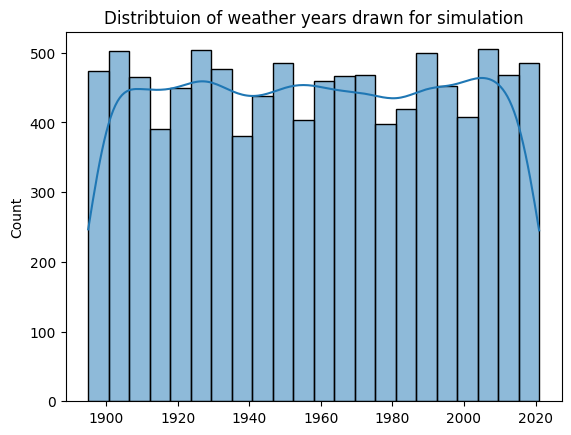

In [59]:
# Develop nonparametric stochastic weather simulations

year_list = np.arange(weather_draw_start_year, mdl_forecast_year-1)
np.random.seed(5) # set's the seed for reproducible results
year_draw = np.random.choice(year_list, num_of_draws, replace=True)

sns.histplot(year_draw, kde = True)
plt.title("Distribtuion of weather years drawn for simulation")
plt.show()


## Simulated yield estiamtes

With years randomly drawn, that sequence of years' weather data set is applied to the state-model; with the forecast year set as the trend variable; the planting progress variable (where applicable) set at 1 to imply planting progress is assumed to be the median pace; and weights applied based on the adjusted planted area data for the forecast year as provided by the Prospective Plantings report. The result is the emperical distribution of yield outcomes based on the historical state-level data of national weather patterns.


In [60]:
wx_draw = pd.DataFrame()

draw_count = 0

for y in year_draw:
    y_df = wx_mdl[wx_mdl['year']==y]
    draw_count += 1
    y_df=y_df.assign(draw_count=draw_count)
    wx_draw = pd.concat([wx_draw, y_df])
    print('Draw: ' + str(draw_count) + '/' + str(num_of_draws)) # include this in the code to monitor the progress of the draws (takes about 1 minute per 1,000 draws)

wx_draw = wx_draw.reset_index(drop=True).rename(columns={'year':'wx_year'})

nonparam_df = wx_draw.merge(wt_df[['state_name', 'wt_value']], on='state_name', how='left', suffixes=['', '_wt']).sort_values('draw_count').reset_index(drop=True)

plt_adj_norm_dict = {'state_name':state_list, 'plt_adj':[1]*len(state_list)}
plt_adj_norm= pd.DataFrame.from_dict(plt_adj_norm_dict)

current_prog_df = prog_mdl[(prog_mdl['year']==mdl_forecast_year)&
                           (prog_mdl['month']==plt_prog_month)&
                           (prog_mdl['day']==plt_prog_day)]
plt_adj_current_dict = {'state_name':state_list} 
plt_adj_current = pd.DataFrame.from_dict(plt_adj_current_dict).merge(current_prog_df, on='state_name', how='left')


if plt_prog_toggle == False:
    state_plt_pred = plt_adj_norm
elif prog_mdl['week_ending'].max() >= pd.to_datetime(str(mdl_forecast_year) + '-' + str(plt_prog_month) + '-' + str(plt_prog_day)):
    state_plt_pred = plt_adj_current
else:
    state_plt_pred = plt_adj_norm


nonparam_df = nonparam_df.merge(state_plt_pred, on='state_name', how='left').rename(columns={'year':'wx_year'})
nonparam_df['year'] = mdl_forecast_year

nonparam_results  = pd.DataFrame()

nonparam_state_list = state_yhat_df['state_name'].unique()

for s in nonparam_state_list:
    mdl_s = state_mdl_dict[s][2]
    df = nonparam_df[nonparam_df['state_name']==s]
    results = df.assign(yhat = mdl_s.predict(df))
    results = df.assign(wt_yhat = results['yhat'] * results['wt_value'])
    nonparam_results = pd.concat([nonparam_results, results])
    print('Success: ' + str(s))

nonparam_national_results = nonparam_results.groupby(['draw_count']).agg({'wt_yhat':np.sum})
print('complete')

Draw: 1/10000
Draw: 2/10000
Draw: 3/10000
Draw: 4/10000
Draw: 5/10000
Draw: 6/10000
Draw: 7/10000
Draw: 8/10000
Draw: 9/10000
Draw: 10/10000
Draw: 11/10000
Draw: 12/10000
Draw: 13/10000
Draw: 14/10000
Draw: 15/10000
Draw: 16/10000
Draw: 17/10000
Draw: 18/10000
Draw: 19/10000
Draw: 20/10000
Draw: 21/10000
Draw: 22/10000
Draw: 23/10000
Draw: 24/10000
Draw: 25/10000
Draw: 26/10000
Draw: 27/10000
Draw: 28/10000
Draw: 29/10000
Draw: 30/10000
Draw: 31/10000
Draw: 32/10000
Draw: 33/10000
Draw: 34/10000
Draw: 35/10000
Draw: 36/10000
Draw: 37/10000
Draw: 38/10000
Draw: 39/10000
Draw: 40/10000
Draw: 41/10000
Draw: 42/10000
Draw: 43/10000
Draw: 44/10000
Draw: 45/10000
Draw: 46/10000
Draw: 47/10000
Draw: 48/10000
Draw: 49/10000
Draw: 50/10000
Draw: 51/10000
Draw: 52/10000
Draw: 53/10000
Draw: 54/10000
Draw: 55/10000
Draw: 56/10000
Draw: 57/10000
Draw: 58/10000
Draw: 59/10000
Draw: 60/10000
Draw: 61/10000
Draw: 62/10000
Draw: 63/10000
Draw: 64/10000
Draw: 65/10000
Draw: 66/10000
Draw: 67/10000
Draw

## Display of results

The results of the simulation are presented below, along with the relevent first and second moment statistical values.

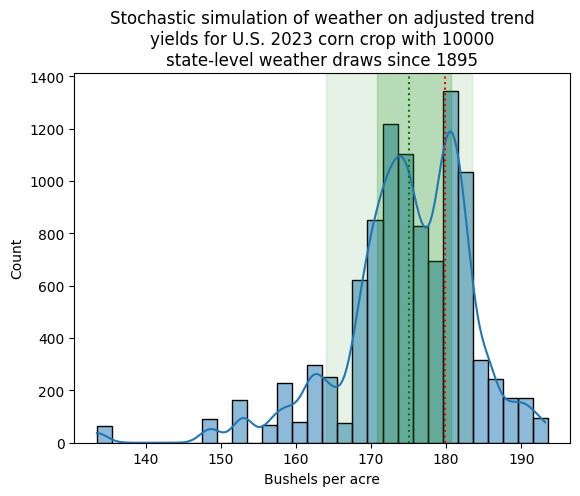

Mid point (non-stocastic) for average weather:  179.90253266348765
Average:  174.81844799460052
Median:  175.05590562477153
IQR:  170.7546163201198  and  180.6846778079611
90% confidence interval:  164.00627444982183  and  183.4084541410386


In [61]:
# Distribution of stochastic results

fig, ax = plt.subplots()
sns.histplot(nonparam_national_results['wt_yhat'], kde=True, binwidth=2)
plt.axvline(x=mid_fcast, ymax=1, color='red', linestyle='dotted')
plt.axvline(x=nonparam_national_results['wt_yhat'].median(), color='green', linestyle='dotted')
plt.axvspan(nonparam_national_results['wt_yhat'].quantile(.25), nonparam_national_results['wt_yhat'].quantile(.75), alpha=0.2, color = 'green')
plt.axvspan(nonparam_national_results['wt_yhat'].quantile(.1), nonparam_national_results['wt_yhat'].quantile(.9), alpha=0.1, color = 'green')
plt.title(f'Stochastic simulation of weather on adjusted trend\nyields for U.S. {mdl_forecast_year} corn crop with {num_of_draws}\nstate-level weather draws since {weather_draw_start_year}')
plt.savefig('National_corn_stochastic_distribution.png')
plt.xlabel('Bushels per acre')
plt.show()

print('Mid point (non-stocastic) for average weather: ', mid_fcast)
print('Average: ', nonparam_national_results['wt_yhat'].mean())
print('Median: ', nonparam_national_results['wt_yhat'].median())
print('IQR: ', nonparam_national_results['wt_yhat'].quantile(.25), ' and ',  nonparam_national_results['wt_yhat'].quantile(.75))
print('90% confidence interval: ', nonparam_national_results['wt_yhat'].quantile(.1), ' and ',  nonparam_national_results['wt_yhat'].quantile(.9))


# Analysis of results

## State-level impact on national yields

One way to evaluate the state-level impact of the stochastic analysis is to show how the stochastic results for each state are distributed.  The main point of reference for the state results is to evaluate how a state's weather could impact that national average state yield.  

The stochastic state results are kept at their harvested-area-weighted yields. The interpretation of this metric is to illustrate the marginal impact of a state's crop to the national average yield. The results are then normalized against the normal weather scenario, which uses average temperature and precipitation levels for all states. The interpretation of this metric is, ultimately, the marginal impact on the national average yield that the respective state has due to the emperically distributed stochastic simulations of weather.

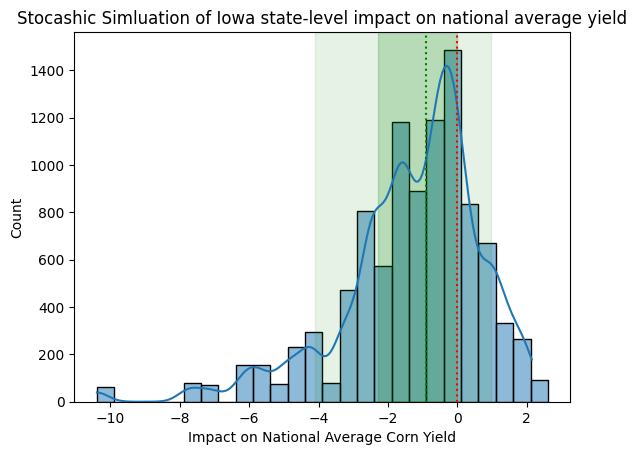

Median stoch. yield impact:  -0.8981025659412509


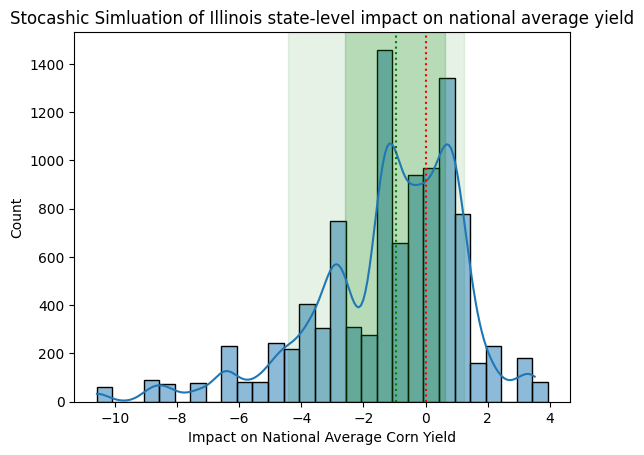

Median stoch. yield impact:  -0.9625330780510986


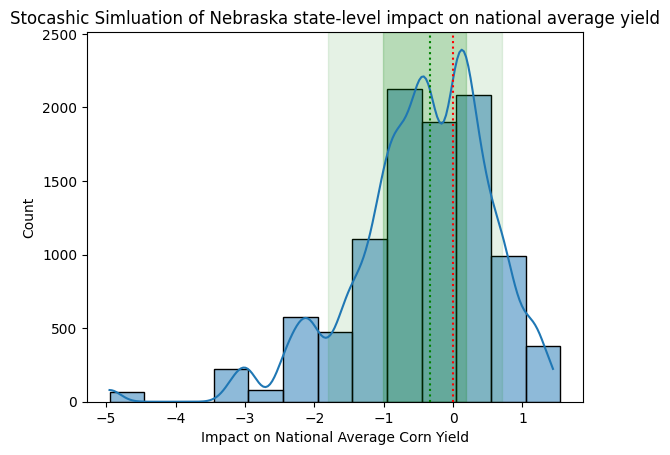

Median stoch. yield impact:  -0.3378478430069549


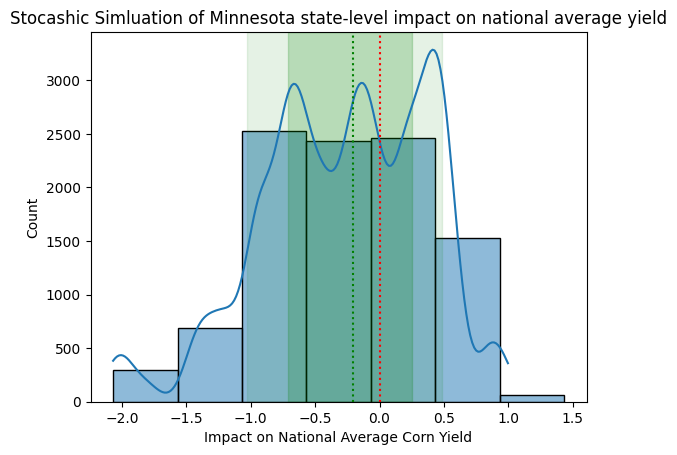

Median stoch. yield impact:  -0.20636463596300914


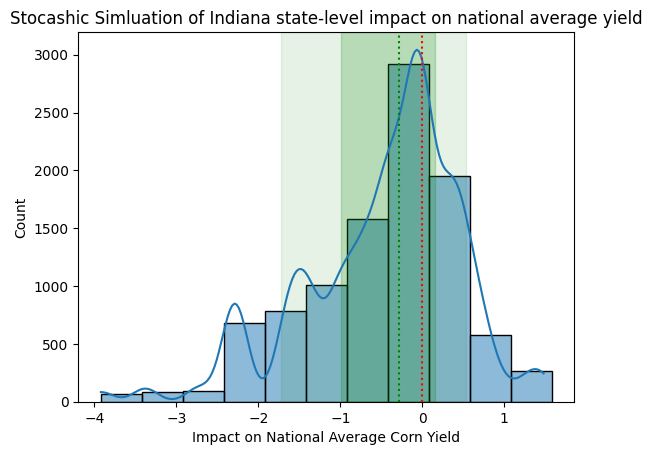

Median stoch. yield impact:  -0.28173654065715503


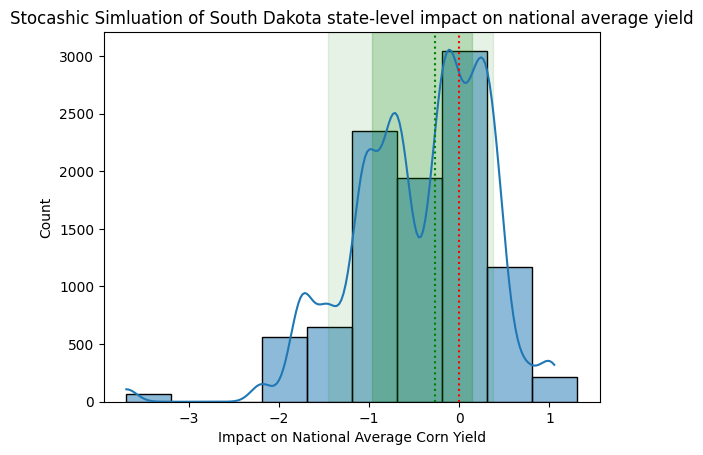

Median stoch. yield impact:  -0.2679070938022363


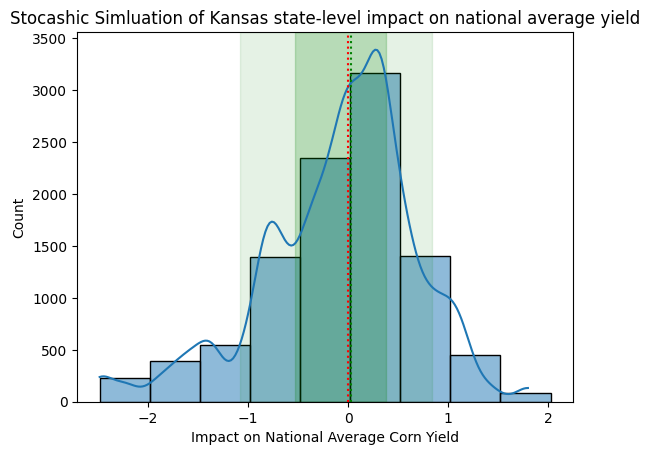

Median stoch. yield impact:  0.032012624521371436


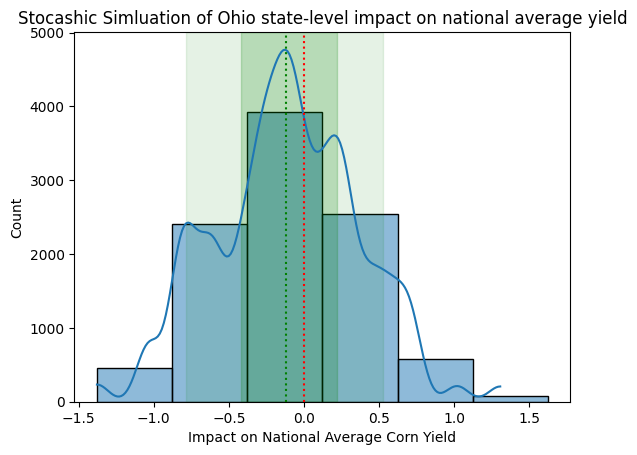

Median stoch. yield impact:  -0.11771438703068515


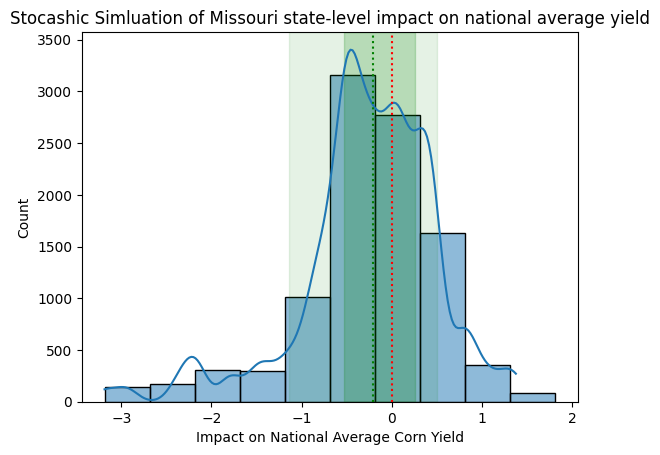

Median stoch. yield impact:  -0.20745909748350666


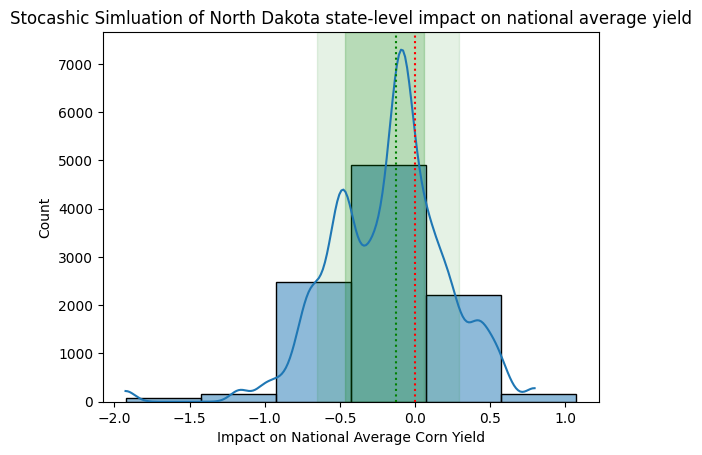

Median stoch. yield impact:  -0.12732160380365354


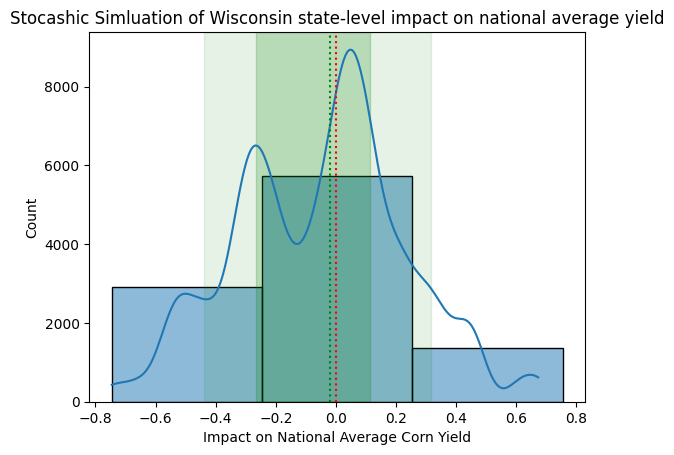

Median stoch. yield impact:  -0.020277891161278205


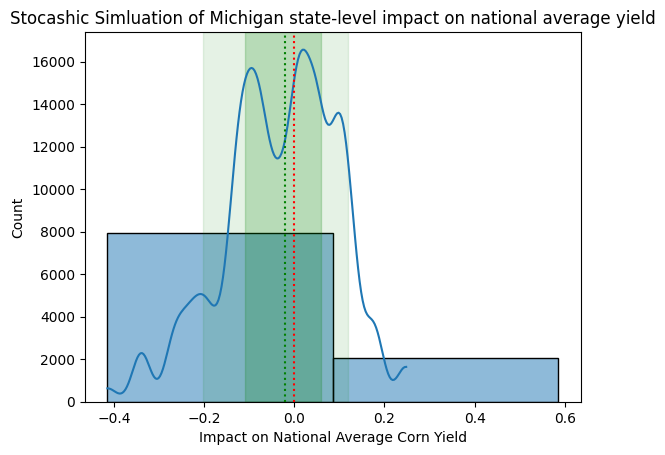

Median stoch. yield impact:  -0.019761984440884284


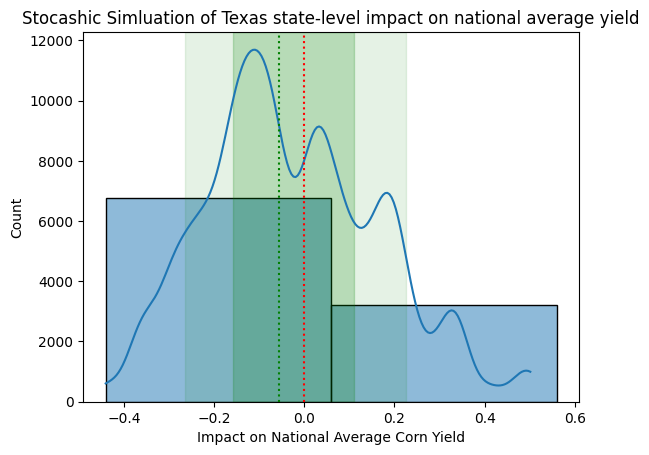

Median stoch. yield impact:  -0.05687873235540275


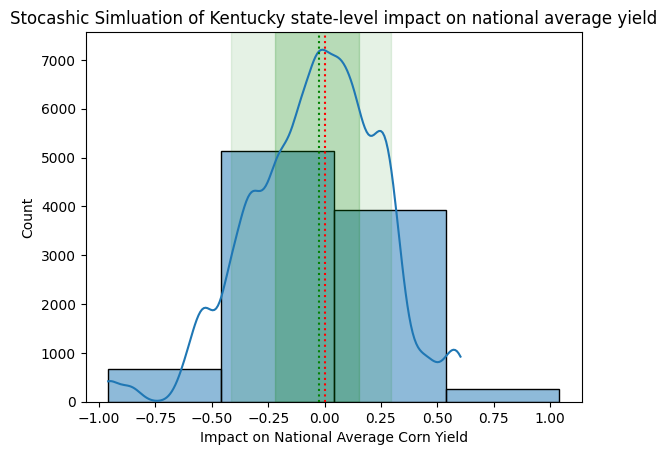

Median stoch. yield impact:  -0.02453452827669489


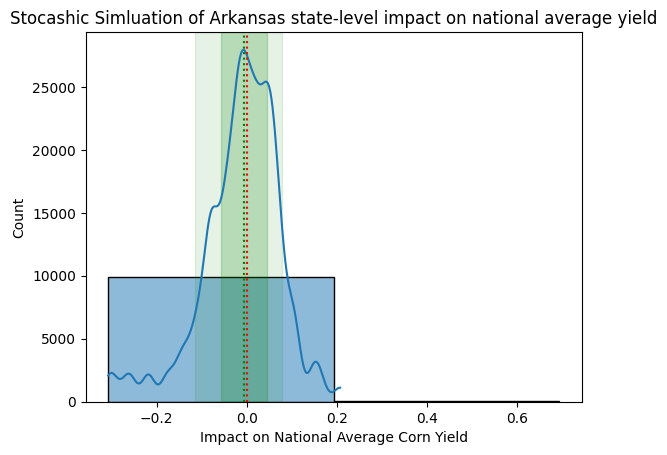

Median stoch. yield impact:  -0.005953118035734173


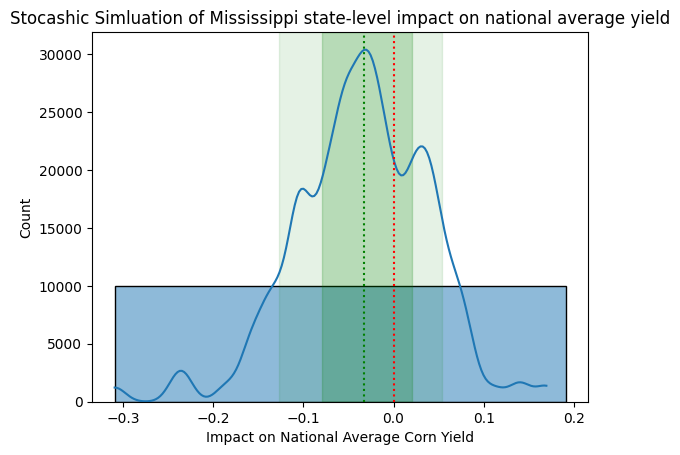

Median stoch. yield impact:  -0.03320818247737045


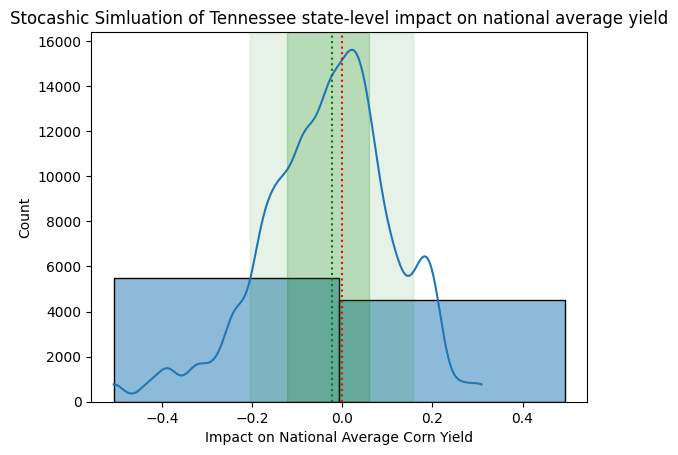

Median stoch. yield impact:  -0.023462893297373943


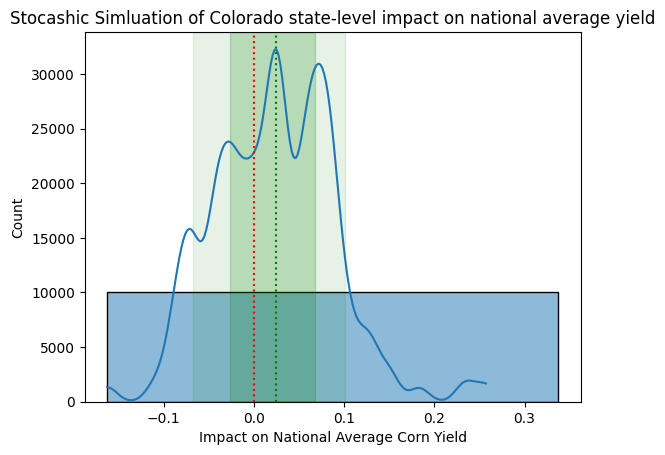

Median stoch. yield impact:  0.02467242488966903


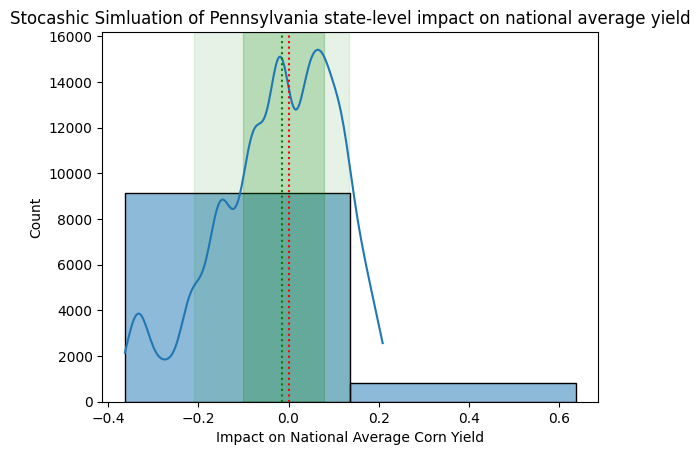

Median stoch. yield impact:  -0.01394083173491234


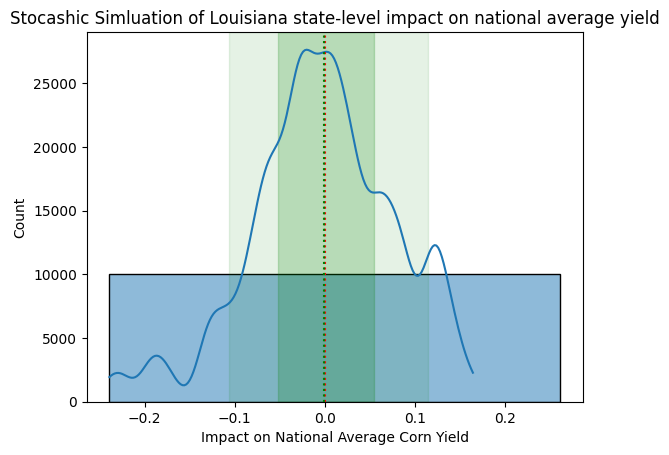

Median stoch. yield impact:  -0.0013787728574246039


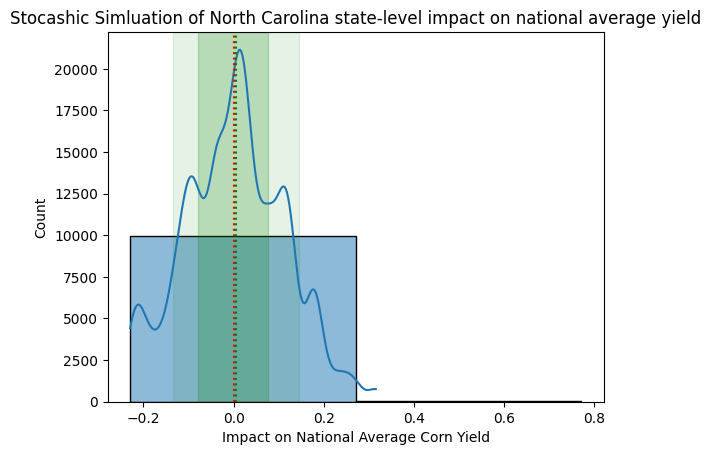

Median stoch. yield impact:  0.005061576340367191


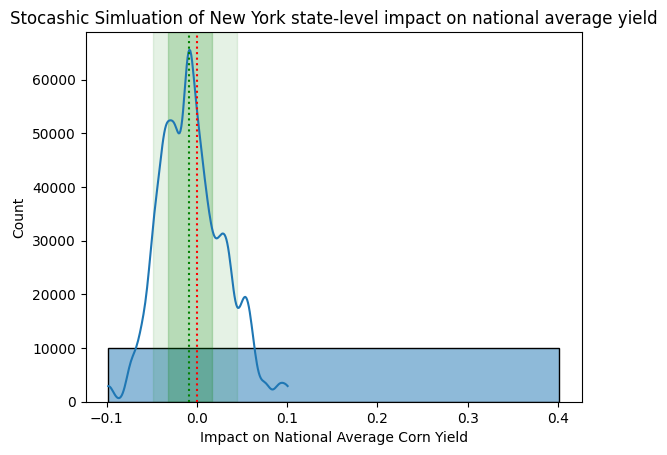

Median stoch. yield impact:  -0.008474344691863589


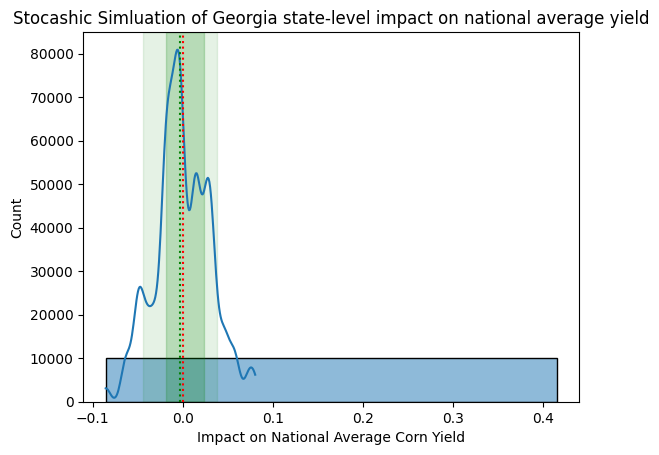

Median stoch. yield impact:  -0.0026995242409142417


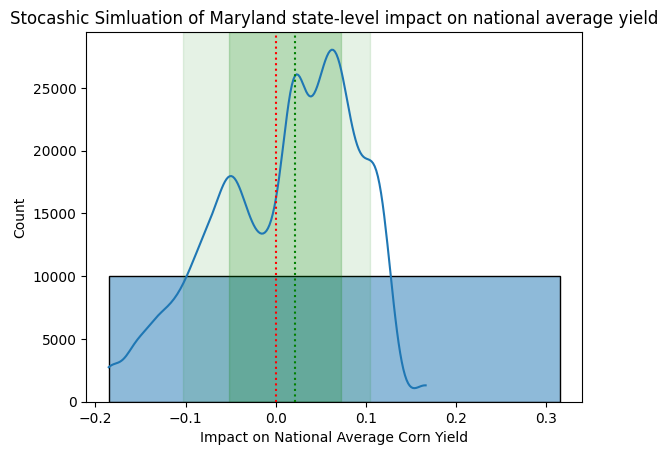

Median stoch. yield impact:  0.021818751105952994


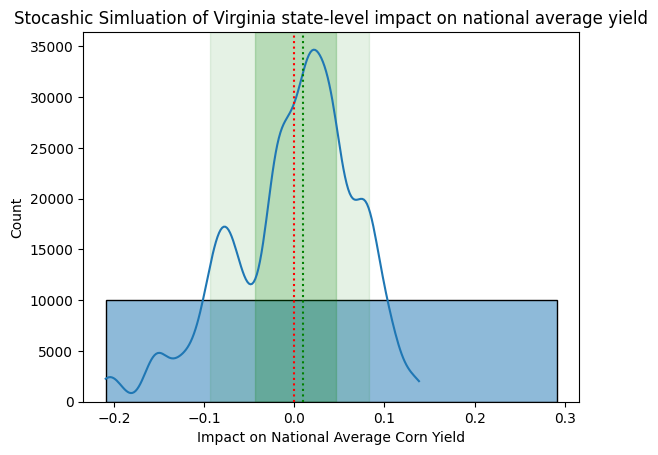

Median stoch. yield impact:  0.009812275419056826


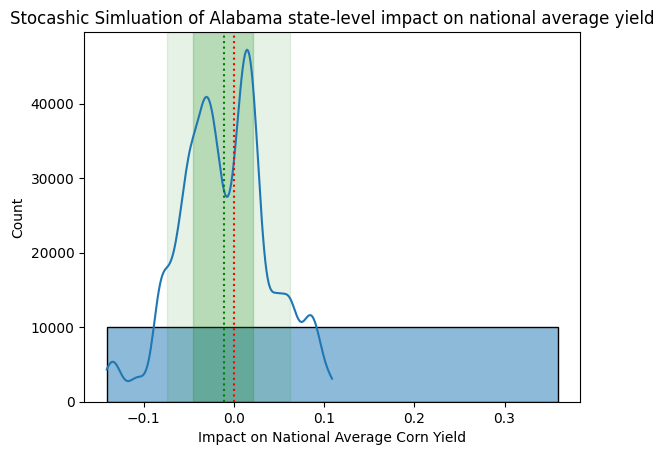

Median stoch. yield impact:  -0.01164385438559723


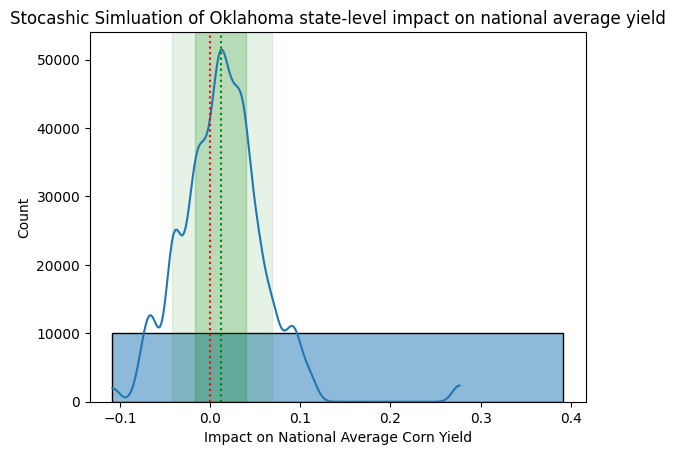

Median stoch. yield impact:  0.011732519384129447


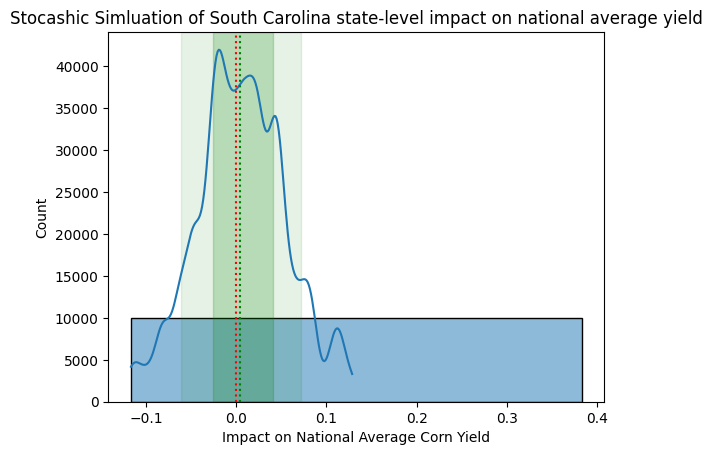

Median stoch. yield impact:  0.0037752381694754478


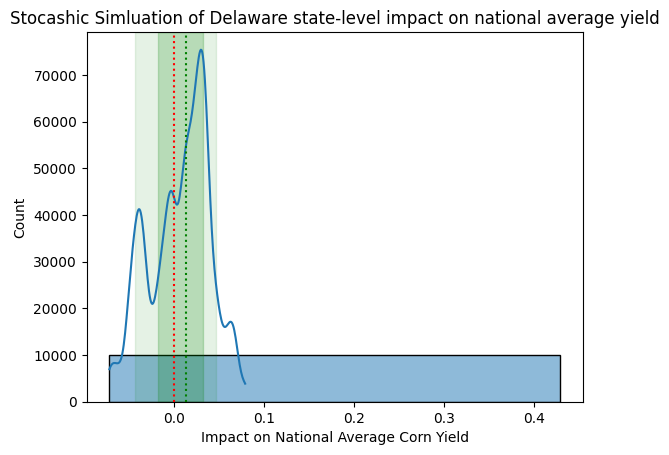

Median stoch. yield impact:  0.013245505810906388


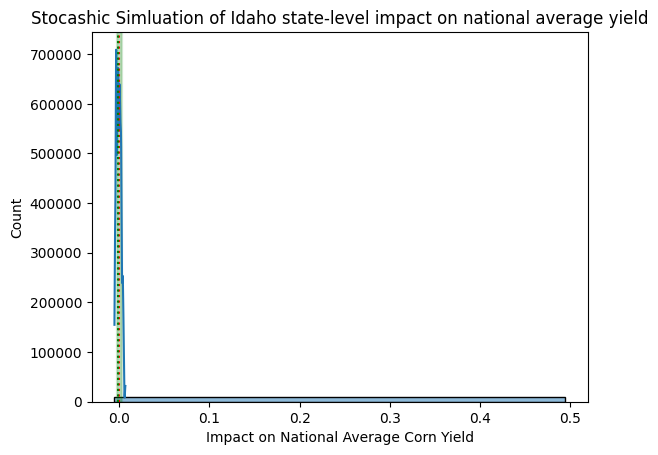

Median stoch. yield impact:  -0.0009090117880109494


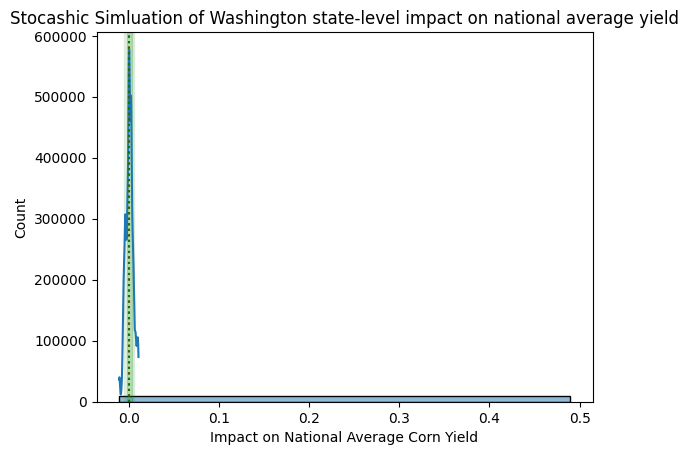

Median stoch. yield impact:  0.0005871787176899845


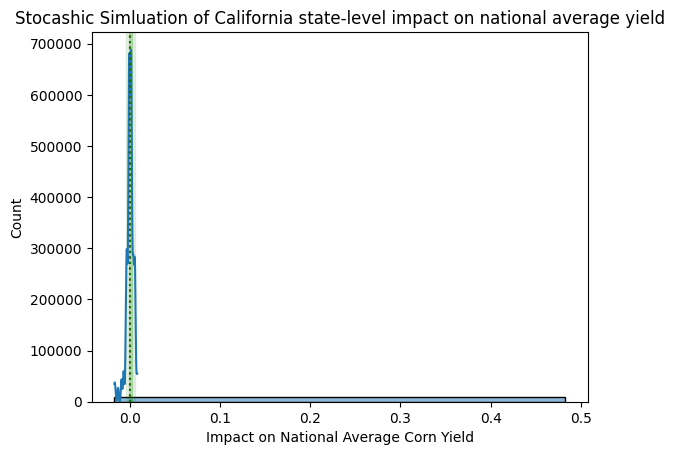

Median stoch. yield impact:  0.00041686613000394


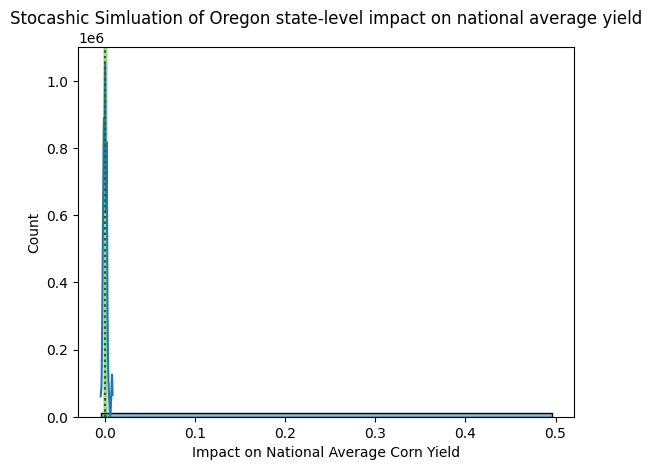

Median stoch. yield impact:  0.00037138043625473127


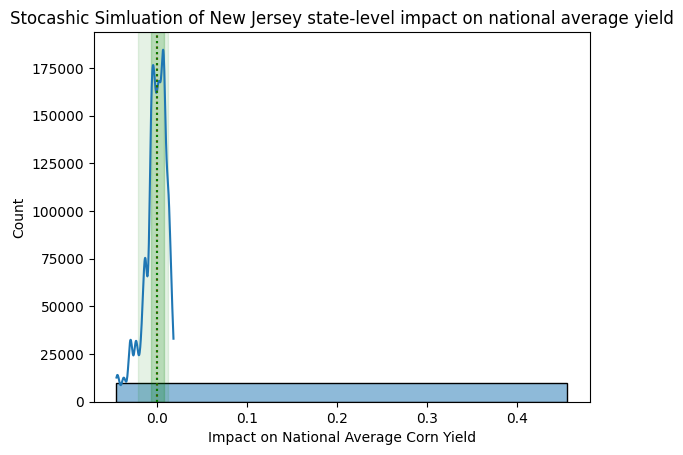

Median stoch. yield impact:  0.00029086547778846283


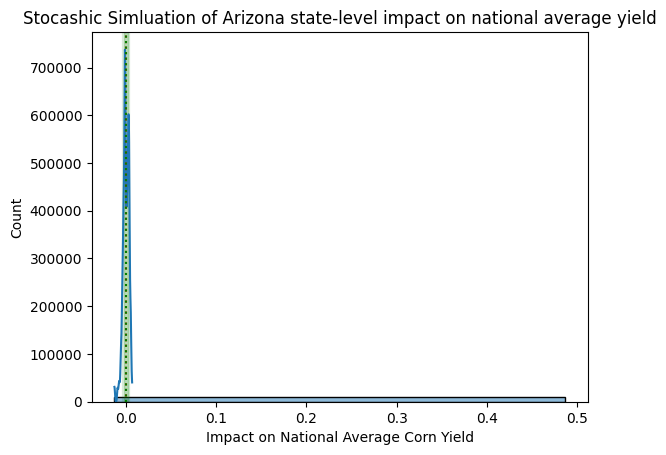

Median stoch. yield impact:  -0.0001985532911624177


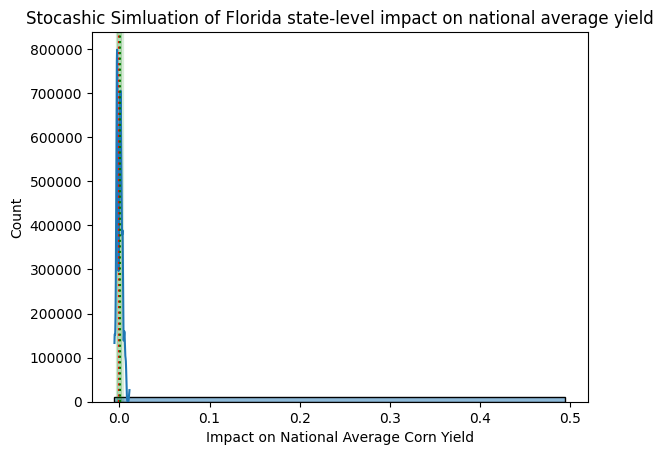

Median stoch. yield impact:  0.0002987282489528148


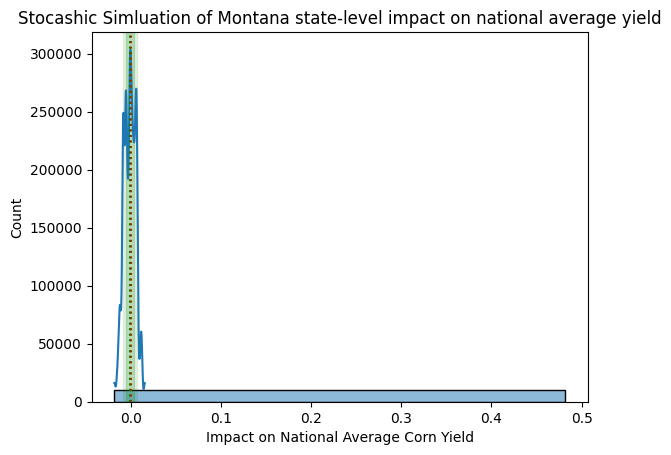

Median stoch. yield impact:  -0.0007806336667605662


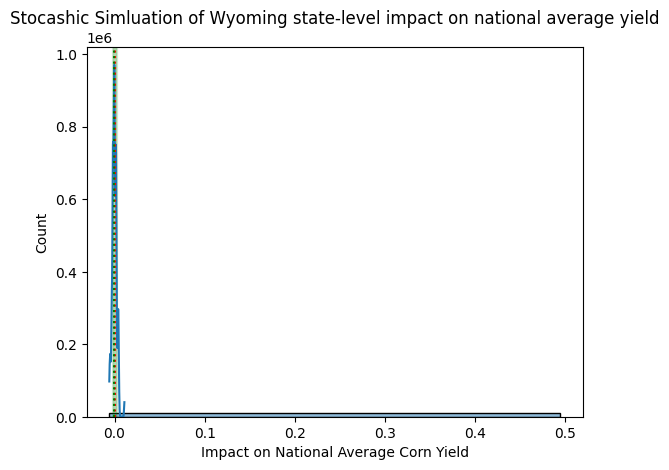

Median stoch. yield impact:  -0.00023650477930586833


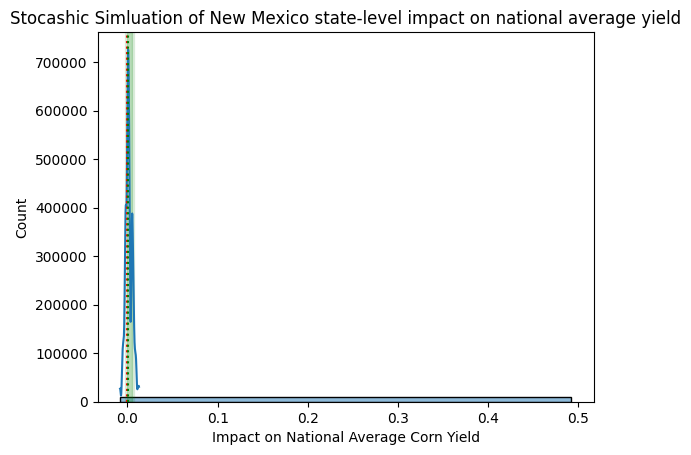

Median stoch. yield impact:  0.0010340535148838786


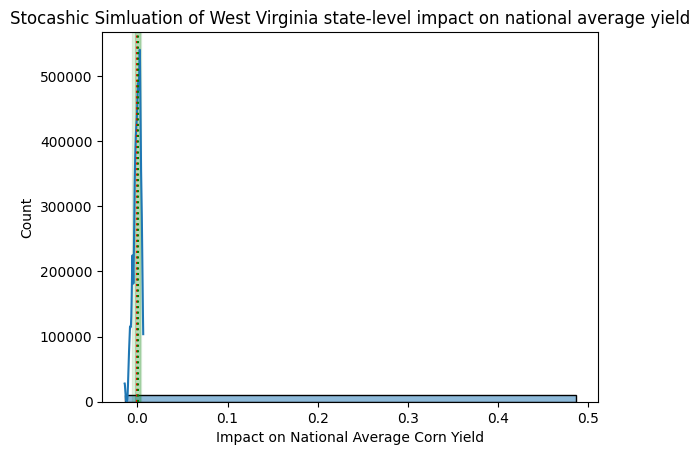

Median stoch. yield impact:  0.00010794858798043178


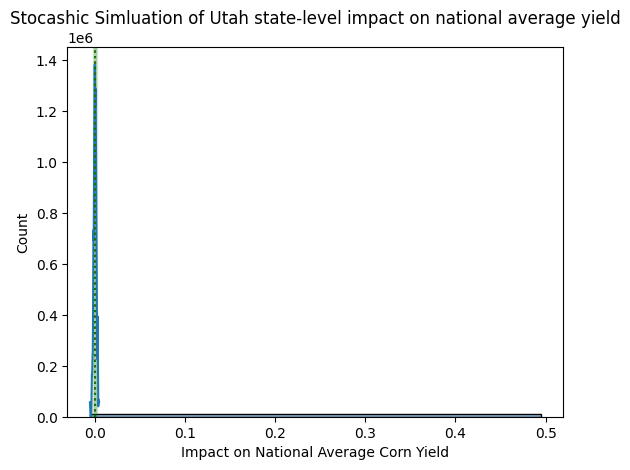

Median stoch. yield impact:  0.00032568880484808854
['Iowa', 'Illinois', 'Nebraska', 'Minnesota', 'Indiana', 'South Dakota', 'Kansas', 'Ohio', 'Missouri', 'North Dakota', 'Wisconsin', 'Michigan', 'Texas', 'Kentucky', 'Arkansas', 'Mississippi', 'Tennessee', 'Colorado', 'Pennsylvania', 'Louisiana', 'North Carolina', 'New York', 'Georgia', 'Maryland', 'Virginia', 'Alabama', 'Oklahoma', 'South Carolina', 'Delaware', 'Idaho', 'Washington', 'California', 'Oregon', 'New Jersey', 'Arizona', 'Florida', 'Montana', 'Wyoming', 'New Mexico', 'West Virginia', 'Utah']


In [62]:
state_mid_viz = state_mid.rename(columns={'wt_yhat':'norm_yhat'})

state_results = nonparam_results.merge(state_mid_viz[['state_name', 'norm_yhat']], on='state_name')
state_impact = state_results.assign(nat_yld_impact = state_results['wt_yhat']-state_results['norm_yhat'])

viz_list = state_impact.sort_values('norm_yhat', ascending=False).state_name.unique().tolist()

for i in viz_list:
    fig1, ax1 = plt.subplots()
    sns.histplot(state_impact[state_impact.state_name==str(i)]['nat_yld_impact'], kde=True, binwidth=.5)
    plt.axvline(x=0, color = 'red', linestyle='dotted')
    plt.axvline(x=state_impact[state_impact.state_name==str(i)]['nat_yld_impact'].median(), color='green', linestyle='dotted')
    plt.axvspan(state_impact[state_impact.state_name==str(i)]['nat_yld_impact'].quantile(.1), state_impact[state_impact.state_name==str(i)]['nat_yld_impact'].quantile(.9), alpha=0.1, color='green')
    plt.axvspan(state_impact[state_impact.state_name==str(i)]['nat_yld_impact'].quantile(.25), state_impact[state_impact.state_name==str(i)]['nat_yld_impact'].quantile(.75), alpha=0.2, color='green')
    plt.title('Stocashic Simluation of ' + str(i) + ' state-level impact on national average yield')
    plt.xlabel('Impact on National Average Corn Yield')
    plt.show()
    print('Median stoch. yield impact: ', state_impact[state_impact.state_name==str(i)]['nat_yld_impact'].median())

print(viz_list)

In [63]:
# print(state_impact[state_impact['wx_year']==2012][['state_name', 'wx_year', 'plt_adj', 'pcpn_7', 'max_temp_7', 'wt_yhat', 'norm_yhat', 'nat_yld_impact']].sort_values('nat_yld_impact', ascending=True).head(40))
#print(state_impact.info())

# Out of sample testing of past data

TEST TEH OUT OF SAMPLE RESULTS ON HISTORICAL SITUATIONS

In [64]:
# Create dataframe to loop process.  Needs to truncate all data to simulate early June analysis and use March Acreage numbers, where available in NASSQS

 ## Set up the parameters for the sampling loop
 
 Testing the estimates for 2005, 2010, 2015, 2018, 2020

In [65]:
test_years = [2005, 2010, 2015, 2018, 2020]

## Turn modelling process into a function



## Pull data from NASS API

The difference between the testing dataframe is that it includes the Acreage data from the March Prosptective Plantings report, rather than the final planted area numbers.